In [2]:
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

warnings.filterwarnings("ignore")

pd.set_option(
    "display.max_columns", None
)  # do not hide any columns every time we run it

In [3]:
from sklearn.datasets import load_breast_cancer

dataset = load_breast_cancer()
df = pd.DataFrame(dataset.data, columns=dataset.feature_names)
df["target"] = dataset.target

In [4]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [5]:
df.tail()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,1.1760,1.256,7.673,158.70,0.010300,0.02891,0.05198,0.02454,0.01114,0.004239,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,0.7655,2.463,5.203,99.04,0.005769,0.02423,0.03950,0.01678,0.01898,0.002498,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,0.4564,1.075,3.425,48.55,0.005903,0.03731,0.04730,0.01557,0.01318,0.003892,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,0.7260,1.595,5.772,86.22,0.006522,0.06158,0.07117,0.01664,0.02324,0.006185,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0
568,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,0.05884,0.3857,1.428,2.548,19.15,0.007189,0.00466,0.00000,0.00000,0.02676,0.002783,9.456,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,1


In [6]:
df.shape

(569, 31)

In [7]:
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,0.405172,1.216853,2.866059,40.337079,0.007041,0.025478,0.031894,0.011796,0.020542,0.003795,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,0.277313,0.551648,2.021855,45.491006,0.003003,0.017908,0.030186,0.006170,0.008266,0.002646,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,6.802000,0.001713,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,0.232400,0.833900,1.606000,17.850000,0.005169,0.013080,0.015090,0.007638,0.015160,0.002248,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,0.324200,1.108000,2.287000,24.530000,0.006380,0.020450,0.025890,0.010930,0.018730,0.003187,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,0.478900,1.474000,3.357000,45.190000,0.008146,0.032450,0.042050,0.014710,0.023480,0.004558,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,542.200000,0.031130,0.135400,0.396000,0.052790,0.078950,0.029840,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [9]:
df.select_dtypes(include="number")

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,1.1760,1.2560,7.673,158.70,0.010300,0.02891,0.05198,0.02454,0.01114,0.004239,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,0.7655,2.4630,5.203,99.04,0.005769,0.02423,0.03950,0.01678,0.01898,0.002498,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,0.4564,1.0750,3.425,48.55,0.005903,0.03731,0.04730,0.01557,0.01318,0.003892,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,0.7260,1.5950,5.772,86.22,0.006522,0.06158,0.07117,0.01664,0.02324,0.006185,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0


In [10]:
object_data = df.select_dtypes(include="object")

print("object Data:")
print(object_data.columns.tolist())

object_data.head()

object Data:
[]


""
0
1
2
3
4


In [11]:
(df.isna().mean() * 100).round(2)

mean radius                0.0
mean texture               0.0
mean perimeter             0.0
mean area                  0.0
mean smoothness            0.0
mean compactness           0.0
mean concavity             0.0
mean concave points        0.0
mean symmetry              0.0
mean fractal dimension     0.0
radius error               0.0
texture error              0.0
perimeter error            0.0
area error                 0.0
smoothness error           0.0
compactness error          0.0
concavity error            0.0
concave points error       0.0
symmetry error             0.0
fractal dimension error    0.0
worst radius               0.0
worst texture              0.0
worst perimeter            0.0
worst area                 0.0
worst smoothness           0.0
worst compactness          0.0
worst concavity            0.0
worst concave points       0.0
worst symmetry             0.0
worst fractal dimension    0.0
target                     0.0
dtype: float64

In [12]:
missing_raw = df.isna().sum().to_frame("Missing_Count")
missing_raw["Missing_%"] = (df.isna().mean() * 100).round(2)

missing_raw.sort_values("Missing_%", ascending=False)

,Missing_Count,Missing_%
mean radius,0,0.0
concavity error,0,0.0
worst fractal dimension,0,0.0
worst symmetry,0,0.0
worst concave points,0,0.0
worst concavity,0,0.0
worst compactness,0,0.0
worst smoothness,0,0.0
worst area,0,0.0
worst perimeter,0,0.0


In [13]:
print("Exact duplicate rows:", df.duplicated().sum())

Exact duplicate rows: 0


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [15]:
df["target"].value_counts()

target
1    357
0    212
Name: count, dtype: int64

<Axes: xlabel='target', ylabel='count'>

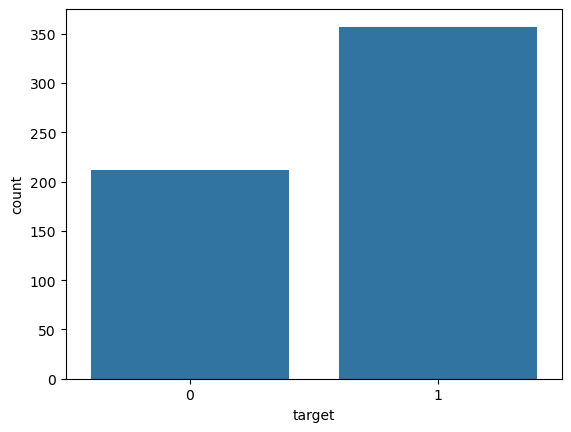

In [16]:
sns.countplot(x="target", data=df)

array([[<Axes: title={'center': 'mean radius'}>,
        <Axes: title={'center': 'mean texture'}>,
        <Axes: title={'center': 'mean perimeter'}>,
        <Axes: title={'center': 'mean area'}>,
        <Axes: title={'center': 'mean smoothness'}>,
        <Axes: title={'center': 'mean compactness'}>],
       [<Axes: title={'center': 'mean concavity'}>,
        <Axes: title={'center': 'mean concave points'}>,
        <Axes: title={'center': 'mean symmetry'}>,
        <Axes: title={'center': 'mean fractal dimension'}>,
        <Axes: title={'center': 'radius error'}>,
        <Axes: title={'center': 'texture error'}>],
       [<Axes: title={'center': 'perimeter error'}>,
        <Axes: title={'center': 'area error'}>,
        <Axes: title={'center': 'smoothness error'}>,
        <Axes: title={'center': 'compactness error'}>,
        <Axes: title={'center': 'concavity error'}>,
        <Axes: title={'center': 'concave points error'}>],
       [<Axes: title={'center': 'symmetry error'}>

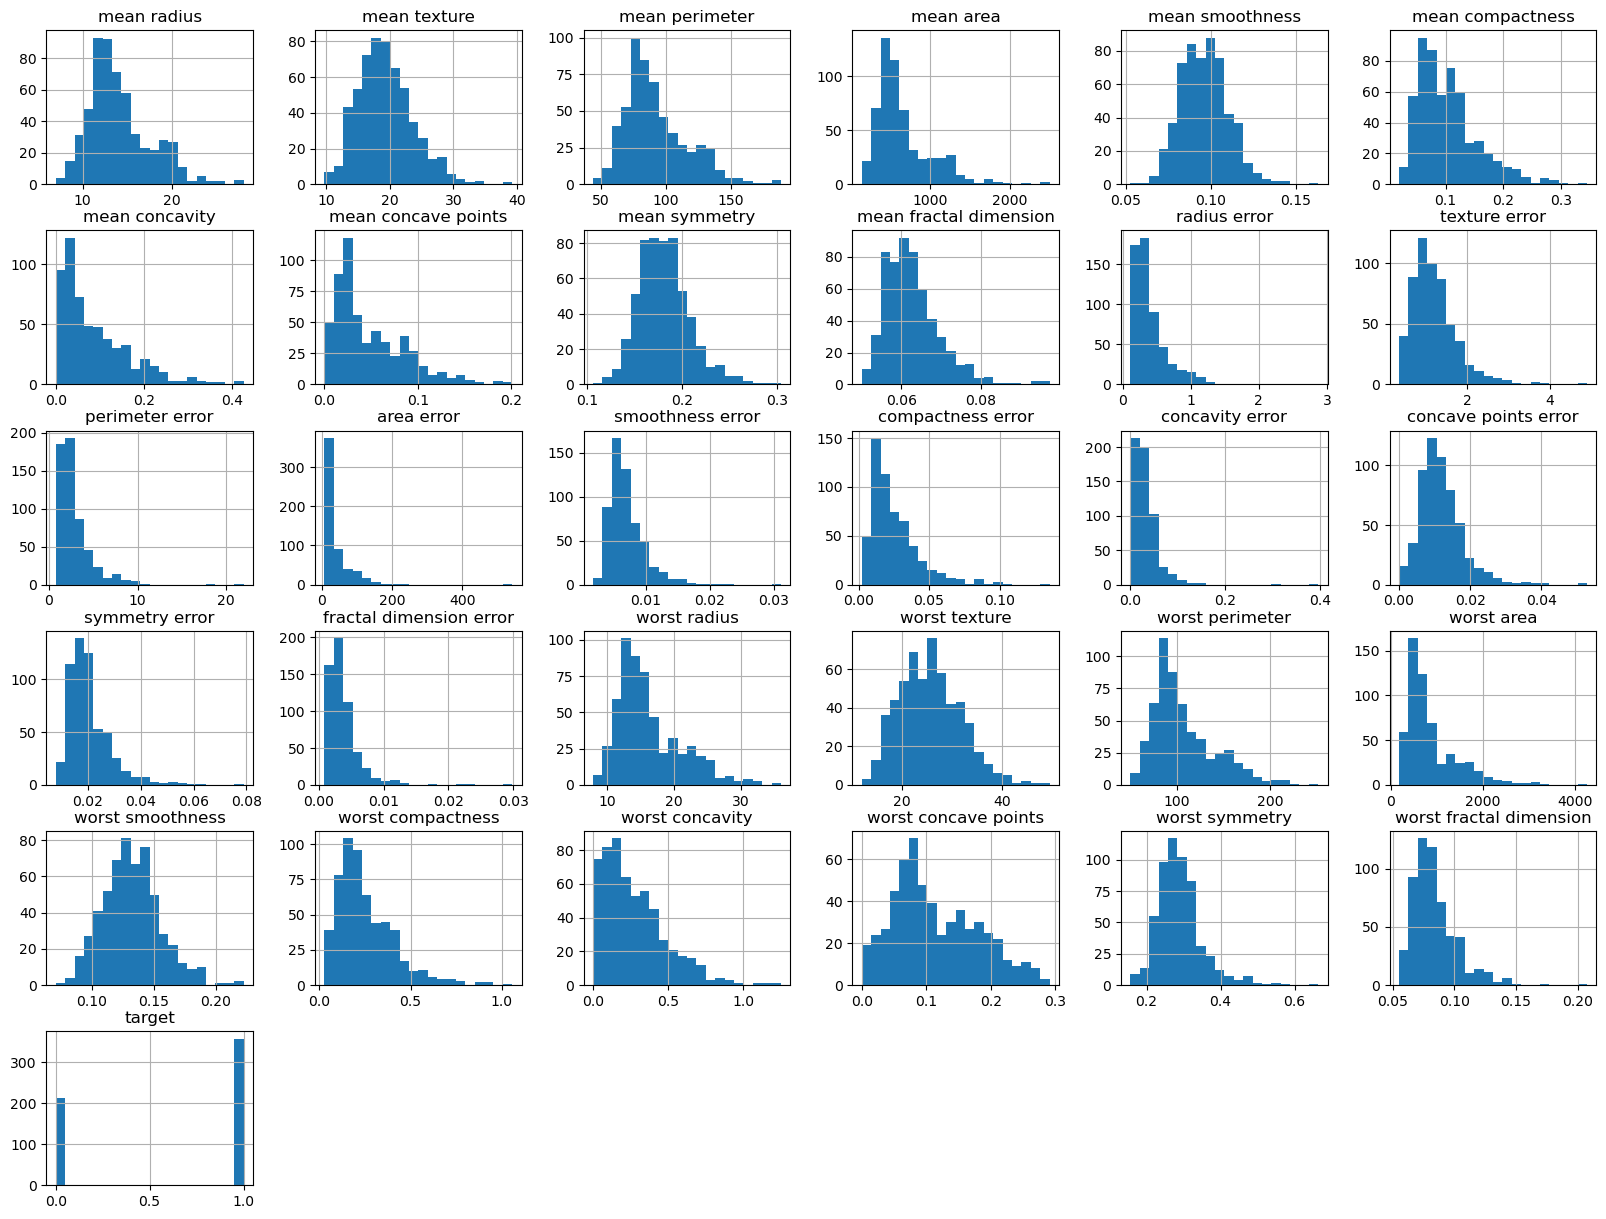

In [17]:
df.hist(figsize=(20, 15), bins=20)

<Axes: xlabel='target', ylabel='mean radius'>

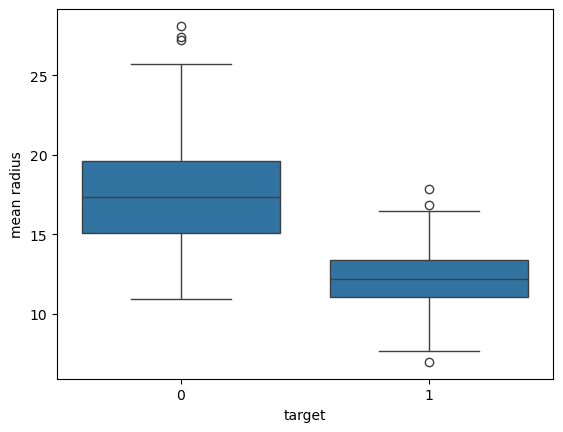

In [18]:
sns.boxplot(x="target", y="mean radius", data=df)

<Axes: xlabel='target', ylabel='worst smoothness'>

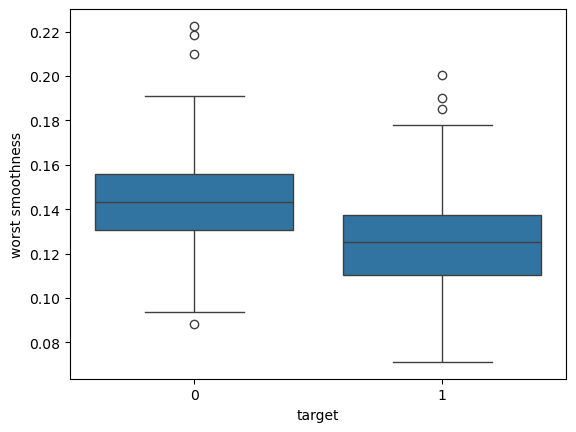

In [19]:
sns.boxplot(x="target", y="worst smoothness", data=df)

In [20]:
# Split X and y
X = df.drop("target", axis=1)
y = df["target"]

In [21]:
# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [22]:
print("Train:", X_train.shape)
print("Test :", X_test.shape)

print("\nTrain class %:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTest class %:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Train: (455, 30)
Test : (114, 30)

Train class %:
target
1    62.64
0    37.36
Name: proportion, dtype: float64

Test class %:
target
1    63.16
0    36.84
Name: proportion, dtype: float64


In [23]:
missing_train = X_train.isna().sum().to_frame("Missing_Count")

missing_train["Missing_%"] = (X_train.isna().mean() * 100).round(2)

missing_train["Data_Type"] = X_train.dtypes.astype(str)

missing_train.sort_values("Missing_%", ascending=False)

,Missing_Count,Missing_%,Data_Type
mean radius,0,0.0,float64
mean texture,0,0.0,float64
worst symmetry,0,0.0,float64
worst concave points,0,0.0,float64
worst concavity,0,0.0,float64
worst compactness,0,0.0,float64
worst smoothness,0,0.0,float64
worst area,0,0.0,float64
worst perimeter,0,0.0,float64
worst texture,0,0.0,float64


In [24]:
from scipy import stats

# Calculate z-scores on training data
z_scores = np.abs(stats.zscore(X_train))

# Create mask: keep rows where ALL features have z < 3
zscore_mask = (z_scores < 3).all(axis=1)
X_train_zscore = X_train[zscore_mask]
y_train_zscore = y_train[zscore_mask]


print(f"Original train size:      {X_train.shape[0]}")
print(f"After Z-Score removal:    {X_train_zscore.shape[0]}")
print(f"Outliers removed:         {X_train.shape[0] - X_train_zscore.shape[0]}")

Original train size:      455
After Z-Score removal:    393
Outliers removed:         62


In [25]:
Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)
IQR = Q3 - Q1

# Create mask: keep rows within IQR bounds
iqr_mask = ~((X_train < (Q1 - 1.5 * IQR)) | (X_train > (Q3 + 1.5 * IQR))).any(axis=1)

X_train_iqr = X_train[iqr_mask]
y_train_iqr = y_train[iqr_mask]

print(f"Original train size:      {X_train.shape[0]}")
print(f"After IQR removal:        {X_train_iqr.shape[0]}")
print(f"Outliers removed:         {X_train.shape[0] - X_train_iqr.shape[0]}")

Original train size:      455
After IQR removal:        314
Outliers removed:         141


In [26]:
# Use the Z-Score cleaned data going forward
X_train_clean = X_train_zscore.copy()
y_train_clean = y_train_zscore.copy()

print(f"Final training size: {X_train_clean.shape[0]} rows")
print(f"Class balance:\n{y_train_clean.value_counts()}")

Final training size: 393 rows
Class balance:
target
1    265
0    128
Name: count, dtype: int64


In [27]:
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train_clean)
X_test_scaled = scaler.transform(X_test)

In [28]:
# Convert back to DataFrame to keep column names
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train_clean.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [29]:
# check if resampling is even needed:
counts = y_train_clean.value_counts()
pcts = (y_train_clean.value_counts(normalize=True) * 100).round(2)

balance = pd.DataFrame({"Count": counts, "Percentage": pcts.astype(str) + "%"})
balance.index = ["Benign (1)", "Malignant (0)"]
print(balance)

               Count Percentage
Benign (1)       265     67.43%
Malignant (0)    128     32.57%


In [30]:
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train_clean)

# Verify balance after SMOTE
counts = y_train_res.value_counts()
pcts = (y_train_res.value_counts(normalize=True) * 100).round(2)
balance = pd.DataFrame({"Count": counts, "Percentage": pcts.astype(str) + "%"})
balance.index = ["Benign (1)", "Malignant (0)"]
print(balance)

               Count Percentage
Benign (1)       265      50.0%
Malignant (0)    265      50.0%


In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Train
lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train_res, y_train_res)

# Predict
y_pred = lr.predict(X_test_scaled)

# Evaluate
print(f"Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print(classification_report(y_test, y_pred, target_names=["Malignant", "Benign"]))

Accuracy: 98.25%
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [32]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

# 1. Base estimator to wrap
estimator = LogisticRegression(random_state=42, max_iter=1000)

# 2. RFECV with Stratified 5-Fold Cross Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rfecv = RFECV(
    estimator=estimator,
    step=1,  # Drop 1 feature at each iteration
    cv=cv,
    scoring="f1",  # Optimize for F1-score (or "roc_auc" / "accuracy")
    min_features_to_select=5,
    n_jobs=-1,
)

# 3. Fit RFECV on training data
rfecv.fit(X_train_res, y_train_res)

# 4. Extract selected features
selected_features_rfe = X_train_res.columns[rfecv.support_].tolist()
dropped_features_rfe = X_train_res.columns[~rfecv.support_].tolist()

print(f"Optimal number of features: {rfecv.n_features_}")
print(f"\nSelected Features ({len(selected_features_rfe)}):")
for feat in selected_features_rfe:
    print(f" - {feat}")

print(f"\nDropped Features ({len(dropped_features_rfe)}):")
for feat in dropped_features_rfe:
    print(f" - {feat}")

Optimal number of features: 18

Selected Features (18):
 - mean texture
 - mean compactness
 - mean concavity
 - mean concave points
 - radius error
 - area error
 - compactness error
 - concave points error
 - fractal dimension error
 - worst radius
 - worst texture
 - worst perimeter
 - worst area
 - worst smoothness
 - worst concavity
 - worst concave points
 - worst symmetry
 - worst fractal dimension

Dropped Features (12):
 - mean radius
 - mean perimeter
 - mean area
 - mean smoothness
 - mean symmetry
 - mean fractal dimension
 - texture error
 - perimeter error
 - smoothness error
 - concavity error
 - symmetry error
 - worst compactness


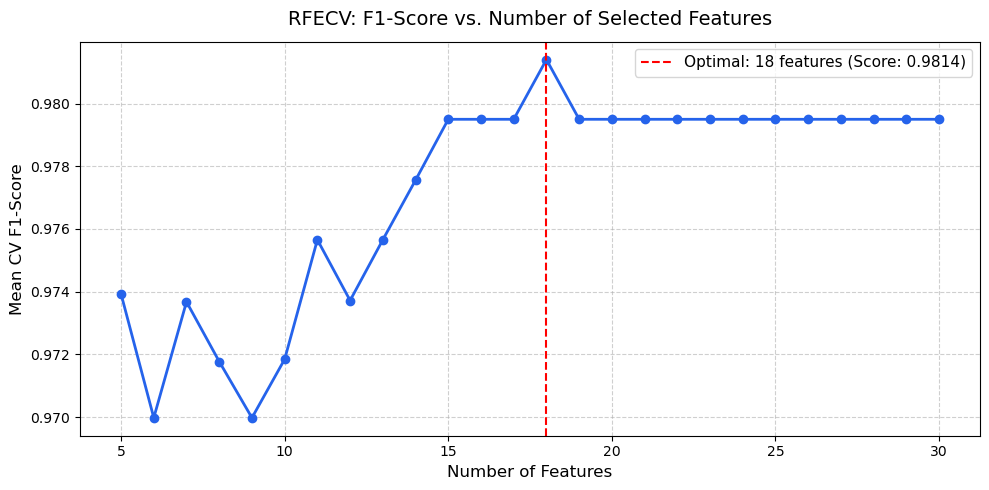

In [33]:
plt.figure(figsize=(10, 5))
feature_counts = range(rfecv.min_features_to_select, len(X_train_res.columns) + 1)
scores = rfecv.cv_results_["mean_test_score"]

plt.plot(feature_counts, scores, marker="o", color="#2563eb", linewidth=2)
plt.axvline(
    x=rfecv.n_features_,
    color="red",
    linestyle="--",
    label=f"Optimal: {rfecv.n_features_} features (Score: {max(scores):.4f})",
)

plt.title("RFECV: F1-Score vs. Number of Selected Features", fontsize=14, pad=12)
plt.xlabel("Number of Features", fontsize=12)
plt.ylabel("Mean CV F1-Score", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

In [34]:
from sklearn.metrics import accuracy_score, classification_report, f1_score

# 1. Baseline: Model trained on ALL 30 features
lr_all = LogisticRegression(random_state=42, max_iter=1000)
lr_all.fit(X_train_res, y_train_res)
y_pred_all = lr_all.predict(X_test_scaled)

# 2. Selected: Model trained on ONLY the 18 selected features
X_train_sel = X_train_res[selected_features_rfe]
X_test_sel = X_test_scaled[selected_features_rfe]

lr_sel = LogisticRegression(random_state=42, max_iter=1000)
lr_sel.fit(X_train_sel, y_train_res)
y_pred_sel = lr_sel.predict(X_test_sel)

# 3. Print comparison
print("=== COMPARISON ON TEST SET ===")
print(
    f"All Features (30)      -> Accuracy: {accuracy_score(y_test, y_pred_all) * 100:.2f}% | F1: {f1_score(y_test, y_pred_all):.4f}"
)
print(
    f"Selected Features (18) -> Accuracy: {accuracy_score(y_test, y_pred_sel) * 100:.2f}% | F1: {f1_score(y_test, y_pred_sel):.4f}\n"
)

print("=== Classification Report (18 Features) ===")
print(classification_report(y_test, y_pred_sel, target_names=["Malignant", "Benign"]))

=== COMPARISON ON TEST SET ===
All Features (30)      -> Accuracy: 98.25% | F1: 0.9861
Selected Features (18) -> Accuracy: 98.25% | F1: 0.9861

=== Classification Report (18 Features) ===
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



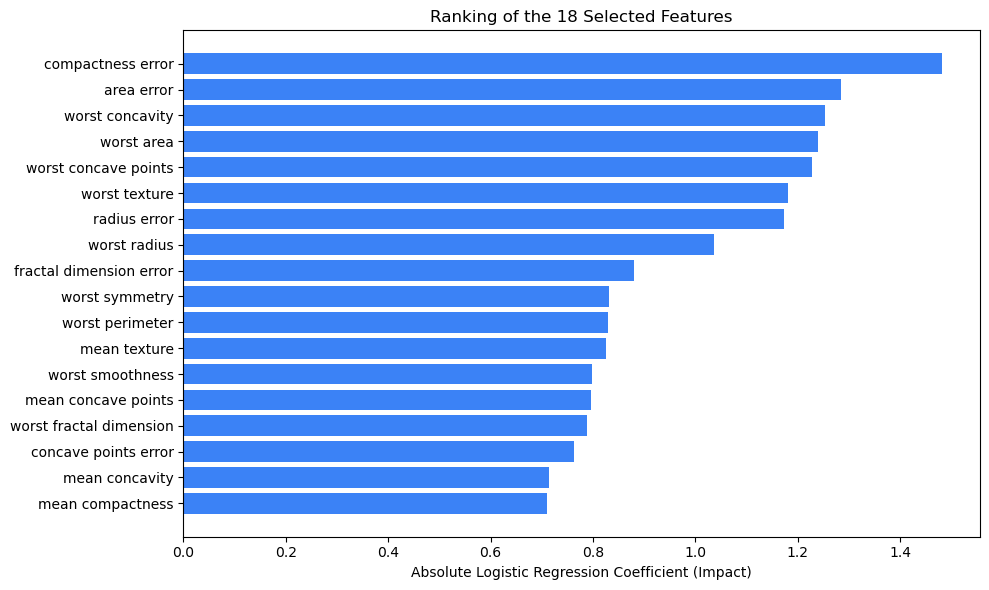

Top 5 Most Influential Features:
                 Feature  Coefficient
6      compactness error     1.481756
5             area error    -1.283485
14       worst concavity    -1.252161
12            worst area    -1.238706
15  worst concave points    -1.228411


In [35]:
# Absolute weights in the logistic regression model
importance = pd.DataFrame(
    {
        "Feature": selected_features_rfe,
        "Coefficient": lr_sel.coef_[0],
        "Abs_Weight": np.abs(lr_sel.coef_[0]),
    }
).sort_values(by="Abs_Weight", ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(importance["Feature"][::-1], importance["Abs_Weight"][::-1], color="#3b82f6")
plt.xlabel("Absolute Logistic Regression Coefficient (Impact)")
plt.title("Ranking of the 18 Selected Features")
plt.tight_layout()
plt.show()

print("Top 5 Most Influential Features:")
print(importance.head(5)[["Feature", "Coefficient"]])